# T31. Asignación de viajes a estaciones y matriz estación → estación

**Objetivo.** Asignar cada viaje del periodo de ajuste a las estaciones de la red elegida en T28 (`lscp_r300_k159`) y construir la matriz origen-destino entre estaciones. Hay dos matrices: la de **demanda asignable** (cada viaje cubierto, a la estación más cercana de cada extremo, sin límites de capacidad) y la de **viajes atendidos** en la simulación de T32 (con patinetes y anclajes limitados, desvíos y rebalanceo).

**Valor.** La tabla de asignación por viaje es la entrada de la fase de consumo (energía por estación) y de la estación de recarga. Las matrices completan el primer requisito del enunciado al nivel de la red propuesta y dicen dónde se pierde servicio.

**Entradas.** Viajes limpios del ajuste, catálogo `T32_estaciones.csv` y resultado de cada solicitud en `datos/procesados/T32_viajes_simulados.parquet` (lo regenera T32).

## 1. Asignación por viaje y conciliación

**Qué queremos ver.** Para cada viaje: la estación más cercana de cada extremo (si está a 300 m o menos), si está cubierto, qué le pasó en la simulación y a qué estaciones fue de verdad. Las cuentas tienen que cuadrar con T32 y cada viaje tiene que tener un único resultado.

**Por qué importa.** Es la tabla que leen las fases de consumo y de recarga. La distancia de acceso se da en línea recta y también estimada a pie con el factor de rodeo de T15 (1,329), que se midió sobre recorridos en patinete: es una aproximación, y T29 muestra que a pie puede ser más en los sectores con barreras.

In [1]:
import numpy as np
import pandas as pd
from IPython.display import display

from comun.config import cargar_config, ruta
from comun.datos import cargar_viajes
from comun.figuras import guardar_figura, plt
from comun.web import exportar
from redes import distancias, extremos, guardar, leer

cfg = cargar_config()
FACTOR_RODEO = cfg["movilidad"]["factor_rodeo"]
franjas = cfg["exploracion"]["franjas_horarias"]
horas = {hora: franja for franja, (inicio, fin) in franjas.items() for hora in range(inicio, fin)}
CAUSAS = ["atendido", "sin_patinete", "sin_anclaje", "sin_cobertura"]

catalogo = leer("T32_estaciones")
red_id = catalogo["network_id"].iloc[0]
radio = float(leer("T28_finalistas").query("network_id == @red_id")["radio_m"].iloc[0])
ids = catalogo["station_id"].to_numpy(str)

viajes = cargar_viajes(periodo="ajuste").reset_index(drop=True)
n = len(viajes)
d = distancias(extremos(viajes), catalogo[["lon", "lat"]].to_numpy(float))
cercana, dist = d.argmin(axis=1), d.min(axis=1)
dentro = dist <= radio

simulados = pd.read_parquet(ruta("viajes_limpios").with_name("T32_viajes_simulados.parquet"))
if len(simulados) != n or not simulados["trip_id"].sort_values().reset_index(drop=True).equals(
        viajes["trip_id"].sort_values().reset_index(drop=True)):
    raise ValueError("T32_viajes_simulados no corresponde a estos viajes. Ejecuta T32 antes que T31.")
viajes = viajes.merge(simulados, on="trip_id", how="left", validate="one_to_one")

salida_local = viajes["tsO"].dt.tz_convert(cfg["datos"]["zona_horaria"])
asignacion = pd.DataFrame({
    "trip_id": viajes["trip_id"],
    "idS": viajes["idS"],
    "tsO": viajes["tsO"],
    "tsD": viajes["tsD"],
    "dis_m": viajes["dis_m"],
    "tt_s": viajes["tt_s"],
    "franja": salida_local.dt.hour.map(horas),
    "tipo_dia": np.where(salida_local.dt.day_of_week < 5, "laborable", "fin_de_semana"),
    "estacion_cercana_origen": np.where(dentro[:n], ids[cercana[:n]], ""),
    "estacion_cercana_destino": np.where(dentro[n:], ids[cercana[n:]], ""),
    "dist_cercana_origen_m": dist[:n],
    "dist_cercana_destino_m": dist[n:],
    "cubierto": dentro[:n] & dentro[n:],
    "resultado": viajes["resultado"],
    "estacion_origen": viajes["estacion_origen"],
    "estacion_destino": viajes["estacion_destino"],
    "desvio_origen_m": viajes["desvio_origen_m"],
    "desvio_destino_m": viajes["desvio_destino_m"],
})
atendido = asignacion["resultado"].eq("atendido")
for lado in ("origen", "destino"):
    recta = asignacion[f"dist_cercana_{lado}_m"] + asignacion[f"desvio_{lado}_m"]
    asignacion[f"acceso_{lado}_m"] = np.where(atendido, recta, np.nan)
    asignacion[f"acceso_pie_{lado}_m"] = asignacion[f"acceso_{lado}_m"] * FACTOR_RODEO

# Comprobaciones: cada viaje un resultado, cubierto ⇔ entra en el inventario, y los atendidos
# salen y llegan a una estación de la red.
assert asignacion["resultado"].isin(CAUSAS).all()
assert (asignacion["cubierto"] == asignacion["resultado"].ne("sin_cobertura")).all()
assert asignacion.loc[atendido, ["estacion_origen", "estacion_destino"]].isin(set(ids)).all().all()
cercana_ok = atendido & asignacion["desvio_origen_m"].eq(0)
assert (asignacion.loc[cercana_ok, "estacion_origen"] == asignacion.loc[cercana_ok, "estacion_cercana_origen"]).all()

asignacion.to_parquet(ruta("viajes_limpios").with_name("T31_asignacion.parquet"), index=False)

conciliacion = (asignacion["resultado"].value_counts().reindex(CAUSAS, fill_value=0)
                .rename_axis("resultado").reset_index(name="viajes"))
conciliacion["pct_solicitudes"] = 100 * conciliacion["viajes"] / n
conciliacion["pct_cubiertas"] = np.where(conciliacion["resultado"].ne("sin_cobertura"),
                                         100 * conciliacion["viajes"] / asignacion["cubierto"].sum(), np.nan)
guardar(conciliacion, "T31_conciliacion")
display(conciliacion.round(2))

acceso = pd.DataFrame([
    {"extremo": lado, "medida": medida, "media_m": s.mean(), "mediana_m": s.median(), "p90_m": s.quantile(.9),
     "pct_desviados": 100 * asignacion.loc[atendido, f"desvio_{lado}_m"].gt(0).mean()}
    for lado in ("origen", "destino")
    for medida, s in (("linea_recta", asignacion.loc[atendido, f"acceso_{lado}_m"]),
                      ("a_pie_estimada", asignacion.loc[atendido, f"acceso_pie_{lado}_m"]))
])
guardar(acceso, "T31_acceso")
display(acceso.round(1))

,resultado,viajes,pct_solicitudes,pct_cubiertas
0,atendido,12865,76.78,95.94
1,sin_patinete,240,1.43,1.79
2,sin_anclaje,304,1.81,2.27
3,sin_cobertura,3347,19.97,NaN


,extremo,medida,media_m,mediana_m,p90_m,pct_desviados
0,origen,linea_recta,160.7,160.9,263.4,0.9
1,origen,a_pie_estimada,213.6,213.9,350.0,0.9
2,destino,linea_recta,163.7,164.2,264.2,1.0
3,destino,a_pie_estimada,217.5,218.2,351.2,1.0


**Conclusiones.**
- Las cuentas cuadran con T32: de las 16 756 solicitudes del ajuste se atienden 12 865 (76,8 %), 240 se pierden por falta de patinete, 304 por falta de anclaje y 3 347 (20,0 %) no tienen estación a 300 m en algún extremo.
- Sobre los 13 409 viajes cubiertos se atiende el 95,9 %.
- **Acceso de los viajes atendidos.** La estación queda de media a 161 m en línea recta en el origen y a 164 m en el destino, y el 90 % la tiene a menos de 264 m. A pie serían unos 214 y 218 m de media y 350 m en el P90.
- Solo el 0,9 % de los orígenes y el 1,0 % de los destinos atendidos acaban en una estación que no es la más cercana. El desvío casi no cambia la asignación.
- La tabla completa queda en `datos/procesados/T31_asignacion.parquet` y se regenera con este notebook.

## 2. Matrices estación → estación

**Qué queremos ver.** Las dos matrices de 159 × 159 estaciones: cuántos pares tienen viajes, cuánto se concentra la demanda en los pares más fuertes, qué parte de los viajes vuelve a la misma estación y cuánta asimetría hay entre ida y vuelta. La asimetría se compara con la que habría si cada viaje de un par fuese de ida o de vuelta al azar (binomial con p = 1/2), como en T23.

**Por qué importa.** Dice si la operación por estaciones se parece a unas pocas líneas fuertes, que justificarían tratarlas aparte, o a una red muy repartida. La asimetría es la parte del desequilibrio que el rebalanceo tiene que corregir.

In [2]:
def matriz(origen, destino):
    m = pd.crosstab(pd.Categorical(origen, categories=ids), pd.Categorical(destino, categories=ids), dropna=False)
    return m.to_numpy()


cub = asignacion["cubierto"]
M_asig = matriz(asignacion.loc[cub, "estacion_cercana_origen"], asignacion.loc[cub, "estacion_cercana_destino"])
M_aten = matriz(asignacion.loc[atendido, "estacion_origen"], asignacion.loc[atendido, "estacion_destino"])
assert M_asig.sum() == cub.sum() and M_aten.sum() == atendido.sum()

entre = distancias(catalogo[["lon", "lat"]].to_numpy(float), catalogo[["lon", "lat"]].to_numpy(float))
io, idd = np.nonzero(M_asig + M_aten)
pares = pd.DataFrame({
    "origen": ids[io], "destino": ids[idd], "distancia_m": entre[io, idd],
    "asignables": M_asig[io, idd], "atendidos": M_aten[io, idd],
})
# Puede ser negativa: un desvío lleva viajes a un par distinto del de las estaciones más cercanas.
pares["diferencia"] = pares["atendidos"] - pares["asignables"]
guardar(pares.sort_values(["asignables", "origen", "destino"], ascending=[False, True, True]),
        "T31_matriz_estaciones")


def desequilibrio_esperado(total):
    """Media de |ida − vuelta| si cada viaje del par fuese ida o vuelta con probabilidad 1/2."""
    from scipy.stats import binom
    k = np.arange(total + 1)
    return float(np.dot(np.abs(2 * k - total), binom.pmf(k, total, .5)))


def indicadores(M):
    total = M.sum()
    fuera = M - np.diag(np.diag(M))
    sup = np.triu_indices_from(M, 1)
    ida, vuelta = fuera[sup], fuera.T[sup]
    con = (ida + vuelta) > 0
    esperado = sum(desequilibrio_esperado(int(t)) for t in (ida + vuelta)[con])
    ordenado = np.sort(M.ravel())[::-1]
    return {
        "viajes": int(total),
        "pares_con_viajes": int((M > 0).sum()),
        "pct_pares_posibles": 100 * (M > 0).sum() / M.size,
        "pct_mismo_origen_destino": 100 * np.trace(M) / total,
        "pct_top10_pares": 100 * ordenado[:10].sum() / total,
        "pct_top1pct_pares": 100 * ordenado[:max(1, int((M > 0).sum() * .01))].sum() / total,
        "pct_viajes_en_pares_de_1": 100 * (M == 1).sum() / total,
        "asimetria_pct": 100 * np.abs(ida - vuelta).sum() / (ida + vuelta).sum(),
        "asimetria_aleatoria_pct": 100 * esperado / (ida + vuelta).sum(),
        "mediana_distancia_m": float(np.median(np.repeat(entre.ravel(), M.ravel()))),
    }


tabla_ind = pd.DataFrame({"asignables": indicadores(M_asig), "atendidos": indicadores(M_aten)})
guardar(tabla_ind.rename_axis("indicador").reset_index(), "T31_indicadores")
display(tabla_ind.round(2))

top = pares.nlargest(10, "asignables").merge(
    catalogo[["station_id", "salidas"]].rename(columns={"station_id": "origen", "salidas": "salidas_origen"}),
    on="origen")
display(top[["origen", "destino", "distancia_m", "asignables", "atendidos"]])

,asignables,atendidos
viajes,13409.00,12865.00
pares_con_viajes,4090.00,4016.00
pct_pares_posibles,16.18,15.89
pct_mismo_origen_destino,12.33,12.55
pct_top10_pares,3.96,4.07
pct_top1pct_pares,9.75,9.90
pct_viajes_en_pares_de_1,13.16,13.81
asimetria_pct,38.43,38.65
asimetria_aleatoria_pct,34.62,35.25
mediana_distancia_m,952.42,952.34


,origen,destino,distancia_m,asignables,atendidos
0,891e8051d07ffff,891e8051d07ffff,0.000000,83,82
1,891e8050037ffff,891e8050037ffff,0.000000,71,70
2,891e8050023ffff,891e8050023ffff,0.000000,66,65
3,891e8051897ffff,891e8051897ffff,0.000000,65,65
4,891e8050023ffff,891e8050037ffff,364.632141,50,49
5,891e8050037ffff,891e8050023ffff,364.632141,45,44
6,891e8051d17ffff,891e8051d07ffff,353.474380,43,44
7,891e8050897ffff,891e8050d4fffff,728.182120,37,34
8,891e805088fffff,891e805088fffff,0.000000,36,36
9,891e8050897ffff,891e8050897ffff,0.000000,35,35


**Conclusiones.**
- **La demanda está muy repartida.** Los 13 409 viajes asignables se reparten en 4 090 de los 25 281 pares posibles (16,2 %). Los diez pares más fuertes solo suman el 4,0 % de los viajes y el 13,2 % de los viajes van por pares con un solo viaje en todo el periodo.
- **Uno de cada ocho viajes vuelve a su estación** (12,3 %). Los tres pares más fuertes son viajes circulares, con 65 a 82 viajes atendidos cada uno. El par más fuerte entre estaciones distintas tiene 49 viajes.
- **La asimetría es poco mayor que la del azar:** 38,4 % frente al 34,6 % esperado si ida y vuelta fuesen igual de probables. La mayor parte del desequilibrio par a par se explica por pares con pocos viajes. El desequilibrio que importa está en el saldo de cada estación, que se ve en la sección 3.
- La matriz de atendidos tiene la misma forma que la asignable: 4 016 pares, el 12,5 % de viajes circulares y una distancia mediana entre estaciones de 952 m. La capacidad limitada no cambia qué pares se usan, solo cuántos viajes pasan.
- Todos los pares están en `T31_matriz_estaciones.csv`, con su distancia, los viajes asignables y los atendidos.

## 3. Saldo de las estaciones por franja y rechazos

**Qué queremos ver.** En los días laborables, el saldo llegadas − salidas de cada estación en la punta de mañana (7–10 h) y en la de tarde (16–20 h), y en qué estaciones se concentran los viajes rechazados por falta de patinete (en la estación de origen) o de anclaje (en la de destino).

**Por qué importa.** Si las estaciones que reciben por la mañana devuelven por la tarde, parte del desequilibrio se compensa solo dentro del día y el rebalanceo nocturno corrige lo que queda. Si los rechazos se concentran en pocas estaciones, basta con agrandar esas.

In [3]:
por_est = pd.DataFrame({
    "station_id": ids,
    "salidas_asignables": M_asig.sum(axis=1), "llegadas_asignables": M_asig.sum(axis=0),
    "salidas_atendidas": M_aten.sum(axis=1), "llegadas_atendidas": M_aten.sum(axis=0),
})
rech = asignacion.loc[cub & ~atendido]
por_est["rechazos_sin_patinete"] = (rech.loc[rech["resultado"].eq("sin_patinete"), "estacion_cercana_origen"]
                                    .value_counts().reindex(ids, fill_value=0).to_numpy())
por_est["rechazos_sin_anclaje"] = (rech.loc[rech["resultado"].eq("sin_anclaje"), "estacion_cercana_destino"]
                                   .value_counts().reindex(ids, fill_value=0).to_numpy())
dias = asignacion["tsO"].dt.tz_convert(cfg["datos"]["zona_horaria"]).dt.date.nunique()
for franja in franjas:
    sel = cub & asignacion["franja"].eq(franja) & asignacion["tipo_dia"].eq("laborable")
    s = asignacion.loc[sel, "estacion_cercana_origen"].value_counts().reindex(ids, fill_value=0)
    ll = asignacion.loc[sel, "estacion_cercana_destino"].value_counts().reindex(ids, fill_value=0)
    por_est[f"saldo_{franja}"] = (ll - s).to_numpy()
guardar(por_est, "T31_estaciones")

n_lab = asignacion.loc[asignacion["tipo_dia"].eq("laborable"), "tsO"].dt.tz_convert(
    cfg["datos"]["zona_horaria"]).dt.date.nunique()
corr = por_est[["saldo_punta_manana", "saldo_punta_tarde"]].corr(method="spearman").iloc[0, 1]
receptoras = por_est.nlargest(5, "saldo_punta_manana")[["station_id", "saldo_punta_manana", "saldo_punta_tarde"]]
print(f"Spearman saldo mañana / tarde (laborables): {corr:.2f}; {n_lab} laborables")
display(receptoras)
print("Rechazos por estación (top 5):")
display(por_est.assign(rech=por_est["rechazos_sin_patinete"] + por_est["rechazos_sin_anclaje"])
        .nlargest(5, "rech")[["station_id", "salidas_asignables", "rechazos_sin_patinete", "rechazos_sin_anclaje"]])

Spearman saldo mañana / tarde (laborables): -0.40; 15 laborables


,station_id,saldo_punta_manana,saldo_punta_tarde
126,891e8052a47ffff,46,-11
72,891e8050c87ffff,35,2
121,891e8052a13ffff,30,-15
37,891e805052bffff,29,-9
129,891e8052a53ffff,27,-10


Rechazos por estación (top 5):


,station_id,salidas_asignables,rechazos_sin_patinete,rechazos_sin_anclaje
103,891e8052327ffff,57,6,5
128,891e8052a4fffff,89,6,5
39,891e8050537ffff,114,6,4
83,891e8050e13ffff,85,1,9
24,891e805019bffff,121,2,7


**Conclusiones.**
- **El patrón de la mañana se invierte por la tarde.** Entre las 159 estaciones, el saldo de la punta de mañana y el de la tarde tienen un Spearman de −0,40 en los 15 laborables del ajuste. La estación que más recibe por la mañana gana 46 patinetes netos en esa franja durante el periodo (unos 3 por laborable) y pierde 11 por la tarde.
- La compensación es parcial: el resto del desequilibrio se acumula de un día a otro, y por eso T32 necesita el rebalanceo nocturno.
- **Los rechazos están repartidos.** Los 544 viajes rechazados se reparten por casi toda la red: las diez estaciones con más rechazos suman solo el 17,6 % y solo 14 estaciones no tienen ninguno. No hay unas pocas estaciones mal dimensionadas; subir el servicio pide más capacidad en general, como ya mostraba la curva de T32.

## 4. Líneas de deseo entre estaciones

**Qué queremos ver.** Los 200 pares de estaciones distintas con más viajes atendidos sobre el mapa, con el tamaño de cada estación según sus salidas, y el saldo de la mañana frente al de la tarde de cada estación.

**Por qué importa.** Es la versión por estaciones de las líneas de deseo de T23. También son los datos que se exportan para la web y la demo.

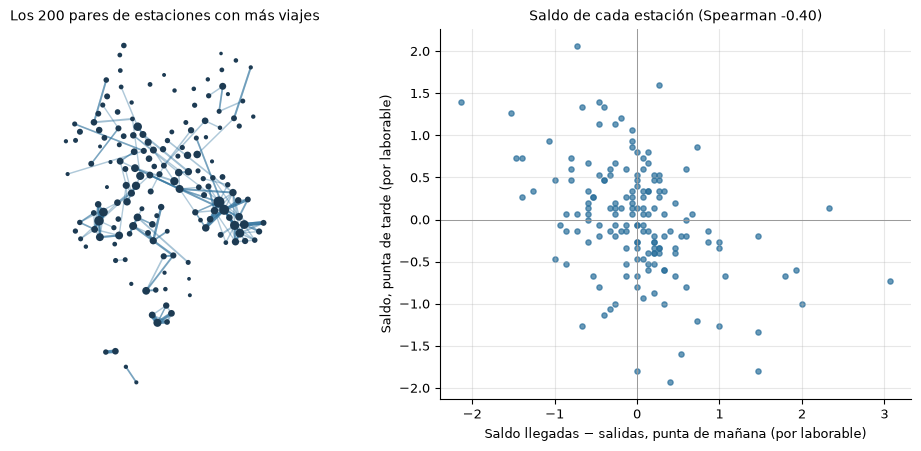

Mediana de distancia de los 200 pares: 718 m; del viaje atendido entre estaciones distintas: 1092 m


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(9.6, 4.4), layout="constrained", width_ratios=[1, 1.15])
lon, lat = catalogo["lon"].to_numpy(), catalogo["lat"].to_numpy()
fuera_diag = pares.loc[pares["origen"].ne(pares["destino"])]
# Hay muchos pares empatados en el corte de los 200: se desempata por identificador para que
# la figura, la web y el texto usen los mismos pares.
top200 = fuera_diag.sort_values(["atendidos", "origen", "destino"], ascending=[False, True, True]).head(200)
pos = {s: i for i, s in enumerate(ids)}
for ax, col in ((axes[0], "atendidos"),):
    lineas = top200.sort_values(col, kind="stable")
    vmax = lineas[col].max()
    for _, f in lineas.iterrows():
        a, b = pos[f["origen"]], pos[f["destino"]]
        ax.plot([lon[a], lon[b]], [lat[a], lat[b]], color="#2a6f9b", lw=.4 + 3.2 * f[col] / vmax,
                alpha=.25 + .6 * f[col] / vmax, solid_capstyle="round")
    ax.scatter(lon, lat, s=4 + por_est["salidas_atendidas"] / por_est["salidas_atendidas"].max() * 60,
               color="#1d3b53", zorder=3, linewidths=0)
    ax.set(title="Los 200 pares de estaciones con más viajes", xticks=[], yticks=[])
    ax.spines[["left", "bottom"]].set_visible(False)
    ax.set_aspect(1 / np.cos(np.radians(lat.mean())))
ax = axes[1]
ax.scatter(por_est["saldo_punta_manana"] / n_lab, por_est["saldo_punta_tarde"] / n_lab, s=14, color="#2a6f9b", alpha=.7)
ax.axhline(0, color="#999", lw=.7)
ax.axvline(0, color="#999", lw=.7)
ax.set(xlabel="Saldo llegadas − salidas, punta de mañana (por laborable)",
       ylabel="Saldo, punta de tarde (por laborable)",
       title=f"Saldo de cada estación (Spearman {corr:.2f})")
guardar_figura(fig, "movilidad", "T31_flujos")
plt.show()

exportar("fase1", "t31_asignacion", {
    "network_id": red_id, "radio_m": radio, "factor_rodeo": FACTOR_RODEO,
    "conciliacion": conciliacion, "acceso": acceso, "indicadores": tabla_ind.rename_axis("indicador").reset_index(),
    "pares_top": top200,
    "estaciones": por_est.merge(catalogo[["station_id", "lon", "lat"]], on="station_id"),
    "correlacion_saldo_puntas": corr, "laborables": n_lab,
})
tipico = np.median(np.repeat(fuera_diag["distancia_m"], fuera_diag["atendidos"]))
print(f"Mediana de distancia de los 200 pares: {top200['distancia_m'].median():.0f} m; "
      f"del viaje atendido entre estaciones distintas: {tipico:.0f} m")

**Conclusiones.**
- **Los flujos fuertes son cortos.** Los 200 pares más fuertes unen estaciones a 718 m de mediana, frente a los 1 092 m del viaje atendido típico entre estaciones distintas. No hay ejes largos que crucen la ciudad.
- **Ida y vuelta.** 94 estaciones tienen saldo de signo contrario en las dos puntas (ganan por la mañana y pierden por la tarde, o al revés) y 49, del mismo signo; 16 tienen saldo nulo en alguna de las dos. Es el patrón de la sección 3.

## Decisiones

| Decisión | Valor propuesto | Evidencia | Periodo | Limitaciones | Qué cambia en el plan |
|---|---|---|---|---|---|
| Asignación por viaje | Estación más cercana a 300 m o menos en cada extremo; la estación real y el resultado salen de la simulación de T32 | `T31_asignacion.parquet`, `T31_conciliacion.csv` | Ajuste | Distancia en línea recta; a pie se estima con el factor de rodeo | La fase de consumo calcula la energía por estación con `estacion_origen` y `estacion_destino` de los viajes atendidos |
| Matriz de referencia | La de viajes atendidos (12 865); la asignable (13 409) queda como demanda sin límite de capacidad | `T31_matriz_estaciones.csv`, `T31_indicadores.csv` | Ajuste | Solo los viajes cubiertos por la red | La estación de recarga usa las llegadas atendidas de cada estación |
| Tratamiento de las líneas fuertes | No hacen falta reglas especiales: los diez pares más fuertes suman el 4 % de los viajes | `T31_indicadores.csv` | Ajuste | Un mes de invierno | — |
| Desequilibrio | Se compensa en parte dentro del día (Spearman −0,40 entre puntas); el resto lo corrige el rebalanceo nocturno | `T31_estaciones.csv`, figura `T31_flujos` | Laborables del ajuste | Solo dos franjas comparadas | T33 compara políticas de rebalanceo |